# Calcular el estilo del equipo

## Librerías

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from pathlib import Path

## Limpieza Wyscout

In [2]:
# Limpiar columnas de Wyscout
def limpiar_dataset_scouting(ruta_archivo):
    # Cargar el archivo Excel
    df = pd.read_excel(ruta_archivo)
    
    nuevas_columnas = []
    sub_metricas_pendientes = []
    
    # Iterar sobre cada nombre de columna original
    for col in df.columns:
        col_str = str(col)
        
        # Si no es una columna vacía/oculta, evaluamos si es una métrica compuesta
        if not col_str.startswith("Unnamed"):
            if " / " in col_str:
                # Separamos las partes (Ej: "Shots", "on target")
                partes = [p.strip() for p in col_str.split("/")]
                metrica_base = partes[0]
                
                # La columna actual se convierte en el total
                nuevas_columnas.append(f"{metrica_base}_Total")
                
                # Definir qué nombres llevarán las siguientes columnas 'Unnamed'
                if len(partes) == 2:
                    # Caso típico (Ej: Tiros / a puerta -> Tiros_a_puerta, Tiros_a_puerta_%)
                    sub_metricas_pendientes = [
                        f"{metrica_base}_{partes[1]}", 
                        f"{metrica_base}_{partes[1]}_%"
                    ]
                else:
                    # Caso múltiple (Ej: Perdidas / Bajas / Medias / Altas)
                    sub_metricas_pendientes = [f"{metrica_base}_{p}" for p in partes[1:]]
            else:
                # Si es una métrica simple (Ej: "Possession, %"), se queda igual
                nuevas_columnas.append(col_str)
                sub_metricas_pendientes = [] 
                
        # Si es una columna oculta ('Unnamed'), se le asigna el nombre pendiente que le toca
        else:
            if sub_metricas_pendientes:
                nuevas_columnas.append(sub_metricas_pendientes.pop(0))
            else:
                # Por seguridad, si sobran 'Unnamed'
                nuevas_columnas.append(col_str)
                
    # Aplicar los nuevos nombres limpios al DataFrame
    df.columns = nuevas_columnas
    
    # Eliminar las filas de encabezado residuales
    df_limpio = df.dropna(subset=['Date', 'Match']).reset_index(drop=True)
    
    print(f"Limpieza completada. El dataset ahora tiene {len(df_limpio.columns)} columnas nombradas correctamente.")
    return df_limpio

In [7]:

ruta_base = Path.cwd().parent.parent / "data" / "udlaspalmas"
rutas = [
    ruta_base / "Team Stats Las Palmas 2324.xlsx",
    ruta_base / "Team Stats Las Palmas 2425.xlsx",
    ruta_base / "Team Stats Las Palmas.xlsx"  # 25-26
]

## Designación del estilo de juego últimas 3 temporadas

In [8]:
metricas = [
    "xG", "Shots_on target_%", "Possession, %", "PPDA", "Passes to final third_Total",
    "Average passes per possession", "Recoveries_High", "Recoveries_Medium", 
    "Recoveries_Low", "Counterattacks_with shots", "Touches in penalty area", 
    "Fouls", "Conceded goals", "Shots against_on target_%", "Lateral passes_Total"
]

In [9]:
# Pesos de cada una de las temporadas, la última en segunda división como este año
pesos_temporada = [0.15, 0.15, 0.70]

In [10]:
lista_dfs = []
for i, ruta in enumerate(rutas):
    # En caso de que no tengas los archivos 2324 y 2425 todavia, esto fallará, 
    # asegúrate de que existan en la carpeta antes de correrlo.
    df_temp = limpiar_dataset_scouting(ruta)
    df_temp['Temporada'] = f"Temp_{i+1}"
    df_temp['Peso_Temp'] = pesos_temporada[i]
    lista_dfs.append(df_temp)

df_global = pd.concat(lista_dfs, ignore_index=True)

Limpieza completada. El dataset ahora tiene 46 columnas nombradas correctamente.
Limpieza completada. El dataset ahora tiene 46 columnas nombradas correctamente.
Limpieza completada. El dataset ahora tiene 46 columnas nombradas correctamente.


In [11]:
# Agrupar y escalar métricas
df_agrupado = df_global.groupby(['Team', 'Temporada', 'Peso_Temp'])[metricas].mean().reset_index()
scaler = StandardScaler()
datos_escalados = scaler.fit_transform(df_agrupado[metricas])

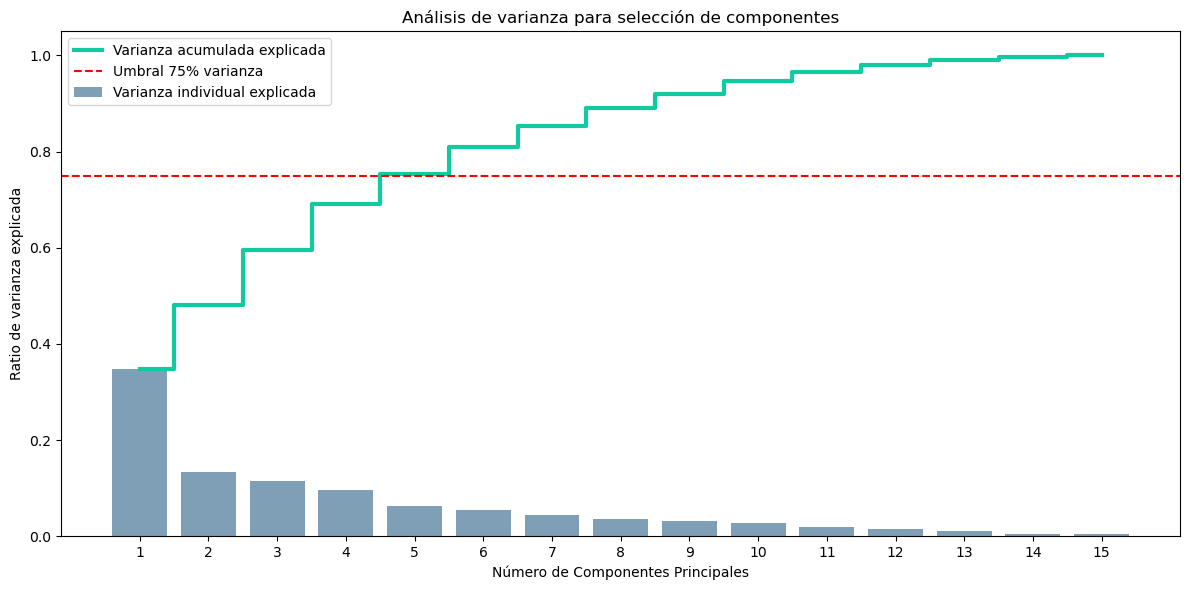

In [15]:
# Ajustar un PCA con todos los componentes posibles para evaluar la varianza
pca_test = PCA()
pca_test.fit(datos_escalados)
exp_var_pca = pca_test.explained_variance_ratio_
cum_sum_eigenvalues = np.cumsum(exp_var_pca)

# Visualización del Scree Plot (Gráfico de Codo)
plt.figure(figsize=(12, 6))

# Barras para varianza individual
plt.bar(range(1, len(exp_var_pca) + 1), exp_var_pca, alpha=0.5, align='center',
        label='Varianza individual explicada', color='#004070')

# Línea para varianza acumulada
plt.step(range(1, len(cum_sum_eigenvalues) + 1), cum_sum_eigenvalues, where='mid',
         label='Varianza acumulada explicada', color='#11CAA0', linewidth=3)

# Umbral del 70-80%
plt.axhline(y=0.75, color='r', linestyle='--', label='Umbral 75% varianza')

plt.ylabel('Ratio de varianza explicada')
plt.xlabel('Número de Componentes Principales')
plt.title('Análisis de varianza para selección de componentes')
plt.xticks(range(1, len(exp_var_pca) + 1))
plt.legend(loc='best')
plt.tight_layout()
plt.show()

In [16]:
# Realizar PCA
pca = PCA(n_components=5)
componentes = pca.fit_transform(datos_escalados)

In [ ]:
# Añadir los 5 ejes al DataFrame
df_agrupado['C1'] = componentes[:, 0]
df_agrupado['C2'] = componentes[:, 1]
df_agrupado['C3'] = componentes[:, 2]
df_agrupado['C4'] = componentes[:, 3]
df_agrupado['C5'] = componentes[:, 4]

# Extraer estilo ponderado UD Las Palmas
df_lp = df_agrupado[df_agrupado['Team'] == 'Las Palmas']
centroide = {
    'C1_Obj': np.average(df_lp['C1'], weights=df_lp['Peso_Temp']),
    'C2_Obj': np.average(df_lp['C2'], weights=df_lp['Peso_Temp']),
    'C3_Obj': np.average(df_lp['C3'], weights=df_lp['Peso_Temp']),
    'C4_Obj': np.average(df_lp['C4'], weights=df_lp['Peso_Temp']),
    'C5_Obj': np.average(df_lp['C5'], weights=df_lp['Peso_Temp'])
}

In [18]:
print("Estilo ponderado (5D)")
print(centroide)

Estilo ponderado (5D)
{'C1_Obj': np.float64(1.3345252022044989), 'C2_Obj': np.float64(-0.6453597900978063), 'C3_Obj': np.float64(-0.667579778506493), 'C4_Obj': np.float64(0.09415064121466338), 'C5_Obj': np.float64(-0.013813402196474877)}


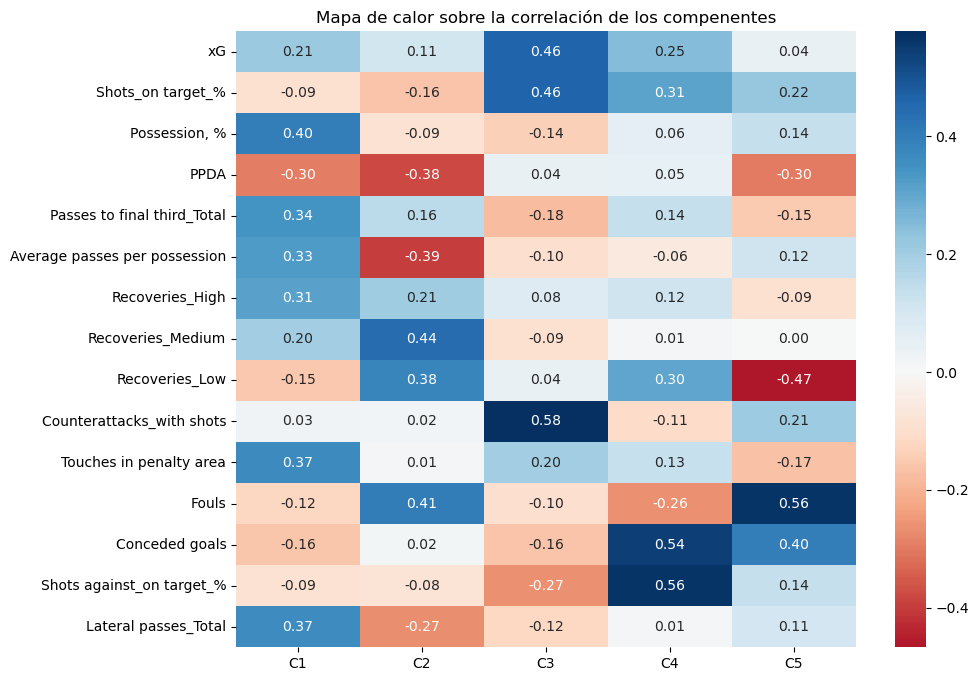

In [ ]:
# Visualización de las cargas (Correlación métrica-componente)
loadings = pd.DataFrame(
    pca.components_.T,
    columns=['C1', 'C2', 'C3', 'C4', 'C5'],
    index=metricas
)

plt.figure(figsize=(10, 8))
sns.heatmap(loadings, annot=True, cmap='RdBu', center=0, fmt=".2f")
plt.title('Mapa de calor sobre la correlación de los compenentes')
plt.show()

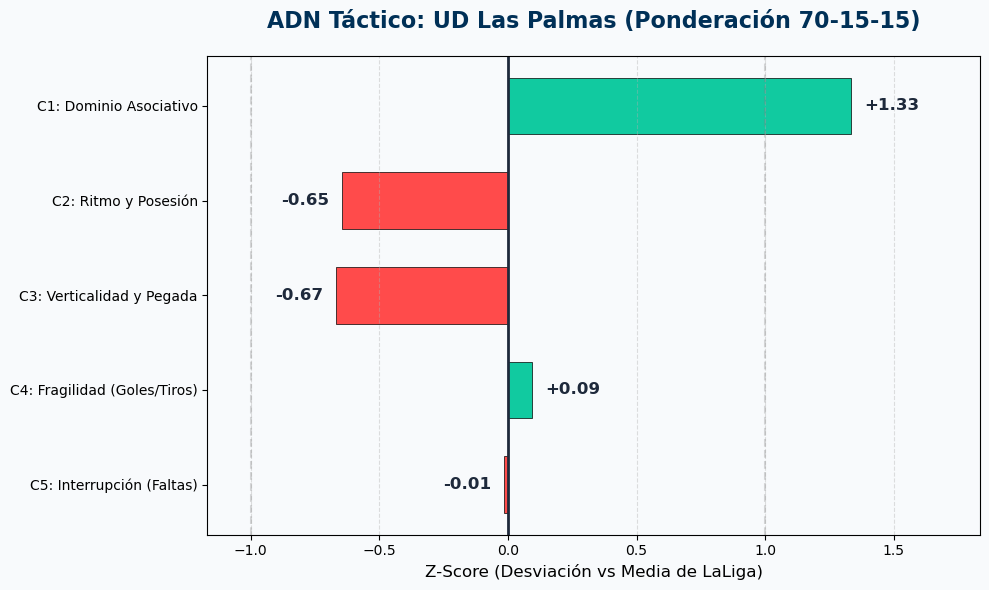

In [ ]:
# Recuperar el cálculo del centroide que hicimos en el código anterior
nombres_ejes = {
    'C1_Obj': 'C1: Dominio Asociativo',
    'C2_Obj': 'C2: Ritmo y Posesión',
    'C3_Obj': 'C3: Verticalidad y Pegada',
    'C4_Obj': 'C4: Fragilidad (Goles/Tiros)',
    'C5_Obj': 'C5: Interrupción (Faltas)'
}

# Transformar el diccionario del centroide para la visualización
ejes = list(nombres_ejes.values())
valores = list(centroide.values())

# Configuración visual del gráfico
plt.figure(figsize=(10, 6), facecolor='#F8FAFC')
ax = plt.gca()
ax.set_facecolor('#F8FAFC')

# Colores condicionales
colores = ['#11CAA0' if val > 0 else '#FF4B4B' for val in valores]

# Crear el gráfico de barras horizontales
bars = plt.barh(ejes, valores, color=colores, height=0.6, edgecolor='black', linewidth=0.5)

# Línea central que es la media de LaLiga
plt.axvline(x=0, color='#1E293B', linestyle='-', linewidth=2)
plt.axvline(x=-1, color='gray', linestyle='--', alpha=0.3)
plt.axvline(x=1, color='gray', linestyle='--', alpha=0.3)

# Etiquetas de valores exactos
for bar, val in zip(bars, valores):
    offset = 0.05 if val > 0 else -0.05
    ha = 'left' if val > 0 else 'right'
    plt.text(val + offset, bar.get_y() + bar.get_height()/2, 
             f"{val:+.2f}", 
             va='center', ha=ha, fontsize=12, fontweight='bold', color='#1E293B')

# Formato y títulos
plt.title('Estilo ponderado de los último 3 años', fontsize=16, fontweight='bold', color='#003057', pad=20)
plt.xlabel('Z-Score', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.4)
plt.xlim(min(valores) - 0.5, max(valores) + 0.5)

# Invertir el eje Y para que C1 quede arriba
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

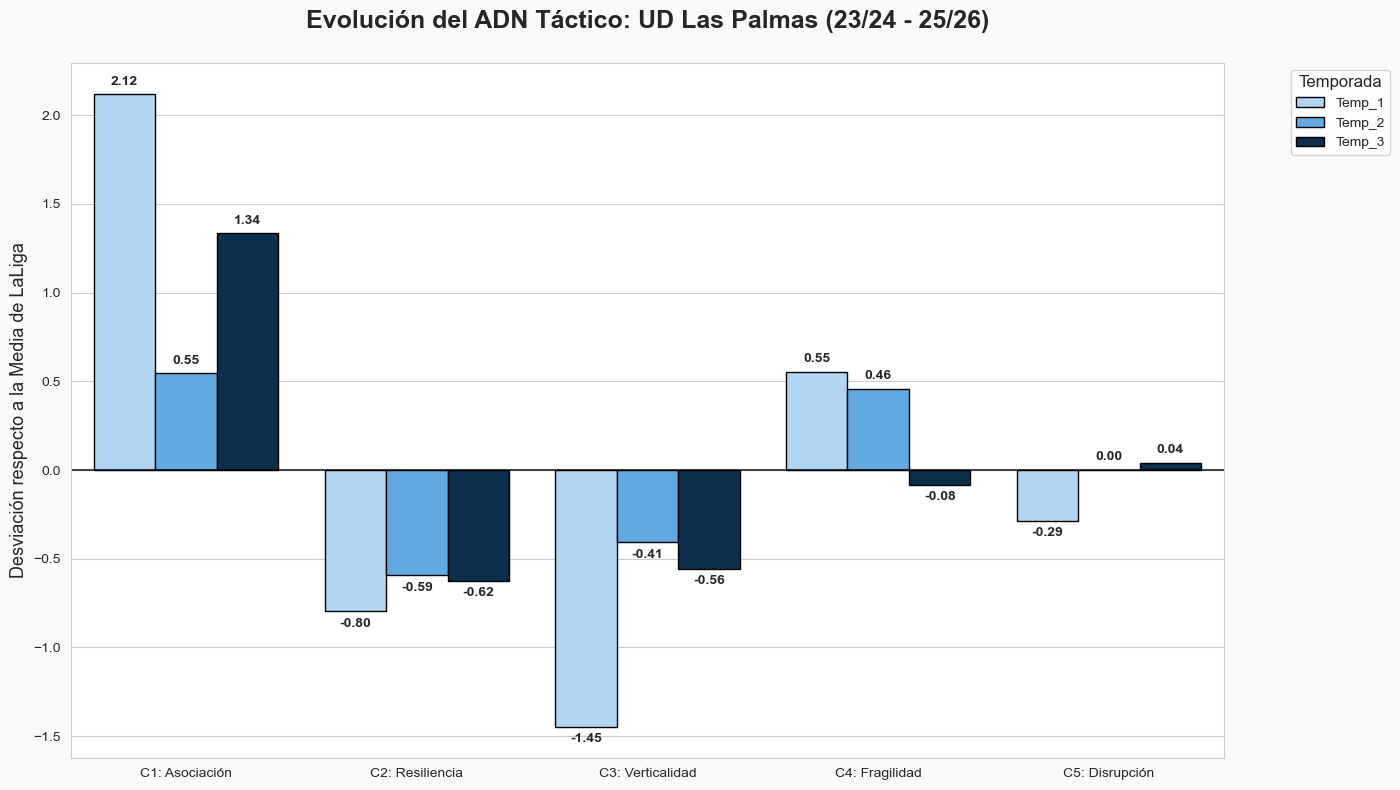

In [ ]:
# Filtrar solo los datos de Las Palmas de las 3 temporadas
df_evolucion = df_agrupado[df_agrupado['Team'] == 'Las Palmas'].copy()

# Reestructurar el DataFrame para que sea fácil de graficar
componentes_cols = ['C1', 'C2', 'C3', 'C4', 'C5']
nombres_reales = ['C1: Asociación', 'C2: Resiliencia', 'C3: Verticalidad', 'C4: Fragilidad', 'C5: Disrupción']

df_plot = df_evolucion.melt(
    id_vars=['Temporada'], 
    value_vars=componentes_cols,
    var_name='Componente', 
    value_name='Z-Score'
)

# Mapear los componentes con la descripción del conjunto de métricas
mapping = dict(zip(componentes_cols, nombres_reales))
df_plot['Componente'] = df_plot['Componente'].map(mapping)

# Creación del gráfico
plt.figure(figsize=(14, 8), facecolor='#F8FAFC')
sns.set_style("whitegrid")

# Paleta de colores que denote progresión
paleta = ["#A5D8FF", "#4DABF7", "#003057"] 

ax = sns.barplot(
    data=df_plot, 
    x='Componente', 
    y='Z-Score', 
    hue='Temporada', 
    palette=paleta,
    edgecolor='black',
    linewidth=1
)

# Detalles
plt.axhline(y=0, color='black', linestyle='-', linewidth=1.5, alpha=0.7) # Media de la liga
plt.title('Evolución según las tres temporadas: UD Las Palmas (23/24 - 25/26)', fontsize=18, fontweight='bold', pad=25)
plt.ylabel('Desviación respecto a la media de LaLiga', fontsize=13)
plt.xlabel('', fontsize=13)
plt.legend(title='Temporada', title_fontsize='12', loc='upper right', bbox_to_anchor=(1.15, 1))

# Añadir etiquetas de valor sobre las barras para mayor precisión técnica
for p in ax.patches:
    if p.get_height() != 0:
        ax.annotate(format(p.get_height(), '.2f'), 
                    (p.get_x() + p.get_width() / 2., p.get_height()), 
                    ha = 'center', va = 'center', 
                    xytext = (0, 9 if p.get_height() > 0 else -9), 
                    textcoords = 'offset points',
                    fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()